In [56]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from Cell2D import Cell2D, draw_array
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import correlate2d
from empiricaldist import Cdf
from utils import three_frame, number_frame, decorate, set_palette
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [57]:
# make a custom color map
palette = sns.color_palette('muted')
colors = 'white', palette[1], palette[0]
cmap = LinearSegmentedColormap.from_list('cmap', colors)

#考虑到后面还需要结婚搬家之类的，参考一下老师的sugar模型，地图（房子）和agent单独做一个class

In [100]:
class Person():

    id = 0

    def __init__(self, loc, group):
        """
        group:
            1 = red / group A
            2 = blue / group B
            3 = red and red / group AA
            4 = blue and blue / group BB
            5 = red and blue / group AB
        """

        # 给每个人一个独立 ID
        # 后面记录组合，和谁呆了一起，就很方便记录
        self.id = Person.id
        Person.id += 1

        # 当前住的位置
        self.loc = tuple(loc)

        # 保存这个人的原始 group
        self.group = group

        # 每个人独立随机一个 openness
        # 0.1, 0.2, ..., 0.9
        self.openness = np.random.randint(1, 10) / 10

        # Happiness has not been calculated yet
        self.satisfaction = None
        self.happy = None

        # key = 邻居的 id value = 连续成为邻居的轮数
        self.neighbors = {}

    def get_info(self):
        """Return this person's current information."""

        return {
            "id": self.id,
            "loc": self.loc,
            "group": self.group,
            "openness": self.openness,
            "satisfaction": self.satisfaction,
            "happy": self.happy,
            "neighbors": self.neighbors.copy()
        }
        
    def update_happiness(self, satisfaction, p):
        """
        Update the current residential happiness.
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.satisfaction = float(satisfaction)
        self.happy = bool(self.satisfaction >= p)

    def update_neighbors(self, current_neighbor_ids):
        """
        current_neighbor_ids: 当前这一轮实际住在周围的人的 ID
        """
        self.neighbors = { neighbor_id: self.neighbors.get(neighbor_id, 0) + 1 for neighbor_id in current_neighbor_ids}

设想，后面的person组合成新的家庭？那么就直接生成新的person，二合一，这样还方便管理，那就不需要房子了，直接在人上修改啊

In [99]:
class house():
    def __init__(self, loc, members = None, max_number = 2): #初始化，地址，房子默认没有人，人数上限是2个
        # 当前的位置
        self.loc = tuple(loc)

        # 住户信息
        self.members = list(members or [])
        self.member_id = None
        self.group = 0
        self.openness = None
        self.max_number = max_number

    def set_resident(self, person): #当每次step之后，就更新数据
        #先初始化当前住户的信息
        new_id = None if person is None else person.id

        # Same resident: no need to read the data again
        if new_id == self.resident_id:
            return False
        
        # 如果住户改变了，那么就更新的信息
        self.resident = person
        self.resident_id = new_id

    def add_member(self, person):
        if(len(self.members) < self.max_number):
            self.members.append(person)
        else:
            print('error');

In [113]:
def locs_where(condition):
    """Find cells where a logical array is True.

    condition: logical array

    returns: list of location tuples (identified by the row/column indices)
    """
    return list(zip(*np.nonzero(condition)))

class Schelling(Cell2D):
    """Represents a grid of Schelling agents."""

    options = dict(mode='same', boundary='wrap')

    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.int8)

    def __init__(self, n, p):
        """Initializes the attributes.

        n: number of rows -- size of the grid
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.p = p
        # 0 is empty house, 1 is agent labelled red, 2 is agent labelled blue
        choices = np.array([0, 1, 2], dtype=np.int8)
        probs = [0.1, 0.45, 0.45]

        # randomly initialize a grid of houses of n by, occupied by two kinds of agents (red and blue)
        # in roughly equal numbers. About 10% of the houses are empty.
        # in [0, 1, 2], o has 10% to be chosen, 1 and 2 each has 45% to be chosen.
        self.array = np.random.choice(choices, (n, n), p=probs) # 这句已经随机生成了 0 / 1 / 2

        #我得知道上一个代码以及随机生成了0，1，2空房子的不同的group，现在得把每个人信息收集起来
        # Dictionary: key = location, for example (3, 5) value = Person object
        # empty cells will NOT be stored here
        
        # 每创建一个新的 Schelling 模型，Person ID 从 0 开始
        Person.id = 0

        self.people = {} #这里是通过当前位置来找当前这个人
        self.people_by_id = {} #通过id来找到这个人

        # 遍历整个 grid，得到所有的person
        for row in range(n):
            for col in range(n):
                group = self.array[row, col] #一共就只有0，1，2
                # 0 是空房，所以不创建 Person
                if group != 0:
                    loc = (row, col) # 创建这个位置上的 Person
                    person = Person(loc, group)
                    self.people[loc] = person # 保存 Person
                    self.people_by_id[person.id] = person #保存id为xx的人的信息

    def get_person_info(self, person_id):
        """Find a Person by ID and return that person's information."""
        person = self.people_by_id.get(person_id)
        if person is None: return None
        return person.get_info()
    
    def count_neighbors(self):
        """Surveys neighboring cells.

        returns: tuple of
            empty: True where cells are empty
            frac_red: fraction of red neighbors around each cell
            frac_blue: fraction of blue neighbors around each cell
            frac_same: fraction of neighbors with the same color
        """
        a = self.array

        # create three arrays that contain False/True (0/1) values
        # to later count the different type of neighbours separately
        empty = a==0
        red = a==1 #先把red和blue单独摘出来方便后面计算每个agent分别有多少个red和blue
        blue = a==2

        # correlate with the kernel, considering the 8 surronding neighbours
        # for agent labelled by red, count how many neighbours are also red agents
        # for agent labelled by blue, count how many neigbours are also blue neighbours
        num_red = correlate2d(red, self.kernel, **self.options)
        num_blue = correlate2d(blue, self.kernel, **self.options)
        
        # for each aget, count the total neighbours (no matter blue or red) it has
        num_neighbors = num_red + num_blue

        # compute fraction of similar neighbors 分别计算red和blue的领居占比
        # Some cells may have no occupied neighbours, so num_neighbors can be 0.
        # Ignore the temporary division warning here.
        with np.errstate(divide='ignore', invalid='ignore'):
            frac_red = num_red / num_neighbors 
            frac_blue = num_blue / num_neighbors

        # no neighbors is considered the same as no similar neighbors 如果周围领居的数为0，就把red和blue的设为0
        # (this is an arbitrary choice for a rare event)

        frac_red[num_neighbors == 0] = 0
        frac_blue[num_neighbors == 0] = 0

        # for each cell, fill the fraction of neighbors with the same color
        # wherever red is True, frac_same gets the corresponding element of frac_red.
        # where red is False, frac_same gets the corresponding element of frac_blue.
        # np.where(condition, value_if_true, value_if_false) 如果这个位置是 red，就用 frac_red；否则用 frac_blue。
        frac_same = np.where(red, frac_red, frac_blue)

        # where red is False could be either blue or empty
        # thus, one additional step:
        # for empty cells, frac_same is NaN
        # 如果是空房子，单独设置一下
        frac_same[empty] = np.nan

        # 先复制原来的 frac_same，保持相同的 grid 大小
        satisfaction = frac_same.copy()
        # 每个人使用自己的 openness 计算 satisfaction
        for loc, person in self.people.items():
            satisfaction[loc] = (frac_same[loc]+ (1 - frac_same[loc]) * person.openness)

        # 如果周围一个邻居都没有，不应该因为 openness 很高就得到很高的 satisfaction。
        # 所以我们仍然按照原模型的思路：no neighbours -> satisfaction = 0
        satisfaction[num_neighbors == 0] = 0

        # 同样的空房子不存在 agent，所以没有satisfaction
        satisfaction[empty] = np.nan

        return empty, frac_red, frac_blue, frac_same, satisfaction

    def segregation(self):
        """Computes the average fraction of similar neighbors.
        returns: fraction of similar neighbors, averaged over cells
        segregation 的含义，如果返回：0.72
        意思：平均而言，每个 agent 的邻居中约 72% 和自己同类型。
        """
        # For quantitative analysis of segregation
        _, _, _, frac_same, _ = self.count_neighbors()
        return np.nanmean(frac_same)

    def update_happiness(self, satisfaction):
        """Update each Person's satisfaction and happy state."""
        #更新每一个人的满足和幸福度

        for loc, person in self.people.items():

            # Satisfaction是当前这个位置的满足程度
            score = satisfaction[loc]
            person.satisfaction = float(score)

            # 更新每一个人的开心程度
            person.happy = bool(score >= self.p)

    def update_neighbors(self):
        """Update every Person's current neighbors."""

        # 得到当前网络的行数
        rows, cols = self.array.shape

        for person in self.people.values():
            row, col = person.loc

            current_neighbor_ids = set() # 用于保存这个人当前所有邻居的ID

            # 检查周围 8 个位置
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):

                    # 不把自己算作邻居
                    if dr == 0 and dc == 0:
                        continue

                    # 是为了实现当前模型使用的boundary='wrap'环形边界
                    neighbor_loc = ((row + dr) % rows, (col + dc) % cols)

                    neighbor = self.people.get(neighbor_loc)

                    if neighbor is not None:
                        current_neighbor_ids.add(neighbor.id)

            person.update_neighbors(current_neighbor_ids)

    def find_candidates(self, person_id, required_rounds=3):
        """Find possible AA or BB pairs."""
        # 列出person_id能够配对的所有人
        candidates = []

        # 只根据 ID 找到当前这个 Person
        person = self.people_by_id.get(person_id)

        if person is None:
            return candidates

        # 只允许单人参加组合, 本人必须开心
        if person.group != 1 and person.group != 2 and person.happy is not True:
            return candidates

        # 检查本人的所有邻居
        for neighbor_id in person.neighbors:

            rounds = person.neighbors[neighbor_id]

            # 连续相邻轮数不足，跳过
            if rounds < required_rounds:
                continue

            # 根据 ID 找到邻居 Person
            neighbor = self.people_by_id.get(neighbor_id)

            # 领居必须存在，邻居也必须是单人，邻居也必须开心
            if neighbor is None and neighbor.group != 1 and neighbor.group != 2 and neighbor.happy is not True:
                continue

            # 避免把 (1, 5) 和 (5, 1) 记录两次，谁的id小就优先记录这个组合，如果重复记录，那么这个组合可能会被计算两次，从而不公平
            if person.id >= neighbor.id:
                continue

            candidates.append(neighbor.id)

        return candidates

    def step(self):
        """Executes one time step.
        returns: fraction of similar neighbors, averaged over cells
        """
        a = self.array
        empty, _, _, frac_same, satisfaction = self.count_neighbors()

        # Update Person objects
        self.update_happiness(satisfaction)

        # 找到不开心的所有人 find the unhappy cells (ignore NaN in frac_same)
        unhappy_locs = [loc for loc, person in self.people.items() if person.happy is False]


        # find the empty cells: the list of (row, column) index tuples for empty location
        empty_locs = locs_where(empty)
        num_empty = len(empty_locs)

        # If there are no empty houses, nobody can move
        if num_empty == 0:
            return np.nanmean(frac_same)

        # shuffle the unhappy cells
        #因为不希望：永远按照 row 0 → row 1 → row 2 的固定顺序搬家。这样模型会产生人为的方向性 bias。随机 shuffle 更合理
        if len(unhappy_locs):
            np.random.shuffle(unhappy_locs)

        # for each unhappy cell, choose a random destination
        num_empty = np.sum(empty)

        for source in unhappy_locs:
            i = np.random.randint(num_empty) #随机得到一个空房子
            dest = empty_locs[i] #准备搬到这个空房子

            # 找到 source 上的 Person
            # 同时删除旧 location 的 dictionary 记录
            # pop 从字典里“取出这个值，并且把这一项删除”
            person = self.people.pop(source)

            # move
            a[dest] = person.group # unhappy agent moves to the empty location, state value updates from 0 to 1 or 2 人先过去
            a[source] = 0 # the unhappy agent's location becomes empty after it moves away 老房子没人了
            person.loc = tuple(dest) # update person's location in class

            self.people[dest] = person # 更新当前class中的people字典
            empty_locs[i] = source # update the empty location list to include the location of unhappy agent that just moved away 把老房子加入空房子列表
            
            # check that the number of empty cells remains the same
            assert num_empty == np.sum(a==0)
        
        # 重新计算新的的幸福度
        _, _, _, updated_frac_same, updated_satisfaction = self.count_neighbors()
        self.update_happiness(updated_satisfaction)

        # 根据搬家后的最终位置更新邻居
        self.update_neighbors()

        # return the average fraction of similar neighbors
        return np.nanmean(updated_frac_same)

    def draw(self):
        """Draws the cells."""
        return draw_array(self.array, cmap=cmap, vmax=2)

接下来就是住房的问题，后面如果出现结婚或则组合的情况，那么这个这个房子对附近邻居产生的影响是根据这个房子里住的人住了哪些人

In [61]:
grid = Schelling(n=100, p=0.4)

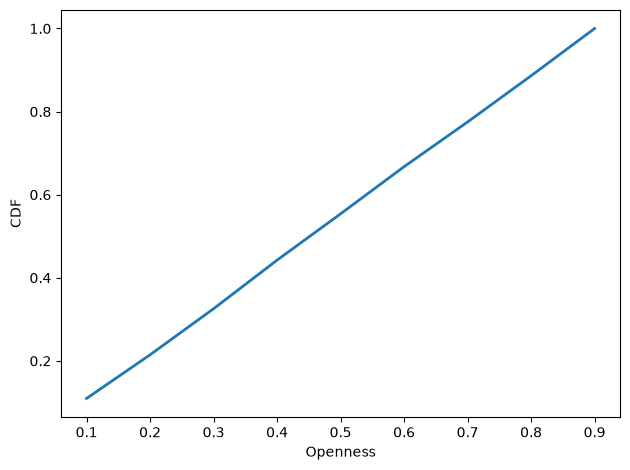

In [62]:
# Check the initial distribution of openness
cdf = Cdf.from_seq(
    person.openness
    for person in grid.people.values()
)

cdf.plot()

decorate(
    xlabel='Openness',
    ylabel='CDF'
)

In [115]:
# p=0，保证所有人开心，因此不会搬家
grid = Schelling(n=10, p=0)

# 第一次记录初始邻居
grid.update_neighbors()


# 使用普通循环找一个至少有一位邻居的人
person = None

for current_person in grid.people.values():
    if len(current_person.neighbors) > 0:
        person = current_person
        break


if person is None:
    print("没有找到拥有邻居的人")

else:
    print("Person ID:", person.id)
    print("第一次:", person.neighbors)

    # 第二次更新邻居
    grid.step()
    print("第二次:", person.neighbors)

    # 第三次更新邻居
    grid.step()
    print("第三次:", person.neighbors)


    # 达到三轮以后，再寻找候选人
    candidates = grid.find_candidates(person.id)

    print(
        "Person",
        person.id,
        "的候选人是:",
        candidates
    )


    print("\n本人信息")
    print("本人 ID:", person.id)
    print("本人位置:", person.loc)
    print("本人 group:", person.group)
    print("本人 happy:", person.happy)


    # 查看所有邻居的信息
    if len(person.neighbors) == 0:
        print("这个人目前没有邻居")

    else:
        for neighbor_id in person.neighbors:

            rounds = person.neighbors[neighbor_id]
            neighbor = grid.people_by_id[neighbor_id]

            print("----------")
            print("邻居 ID:", neighbor.id)
            print("邻居位置:", neighbor.loc)
            print("邻居 group:", neighbor.group)
            print("邻居 happy:", neighbor.happy)
            print("邻居 openness:", neighbor.openness)
            print("连续相邻轮数:", rounds)


Person ID: 0
第一次: {1: 1, 9: 1, 10: 1, 17: 1, 85: 1, 86: 1, 93: 1}
第二次: {1: 2, 9: 2, 10: 2, 17: 2, 85: 2, 86: 2, 93: 2}
第三次: {1: 3, 9: 3, 10: 3, 17: 3, 85: 3, 86: 3, 93: 3}
Person 0 的候选人是: [1, 9, 10, 17, 85, 86, 93]

本人信息
本人 ID: 0
本人位置: (0, 0)
本人 group: 2
本人 happy: True
----------
邻居 ID: 1
邻居位置: (0, 1)
邻居 group: 2
邻居 happy: True
邻居 openness: 0.3
连续相邻轮数: 3
----------
邻居 ID: 9
邻居位置: (0, 9)
邻居 group: 1
邻居 happy: True
邻居 openness: 0.6
连续相邻轮数: 3
----------
邻居 ID: 10
邻居位置: (1, 0)
邻居 group: 1
邻居 happy: True
邻居 openness: 0.2
连续相邻轮数: 3
----------
邻居 ID: 17
邻居位置: (1, 9)
邻居 group: 1
邻居 happy: True
邻居 openness: 0.9
连续相邻轮数: 3
----------
邻居 ID: 85
邻居位置: (9, 0)
邻居 group: 2
邻居 happy: True
邻居 openness: 0.3
连续相邻轮数: 3
----------
邻居 ID: 86
邻居位置: (9, 1)
邻居 group: 2
邻居 happy: True
邻居 openness: 0.5
连续相邻轮数: 3
----------
邻居 ID: 93
邻居位置: (9, 9)
邻居 group: 2
邻居 happy: True
邻居 openness: 0.6
连续相邻轮数: 3


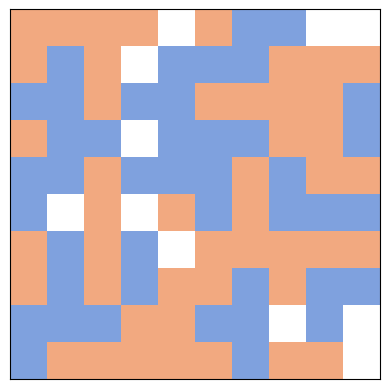

In [105]:
grid.draw()

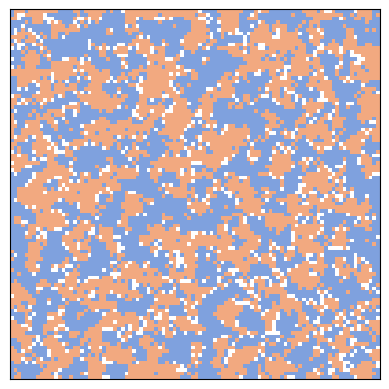

In [64]:
grid = Schelling(n=100, p=0.76)
grid.animate(frames=10, interval=0.1) #animate这个function里面有step会自己跳动

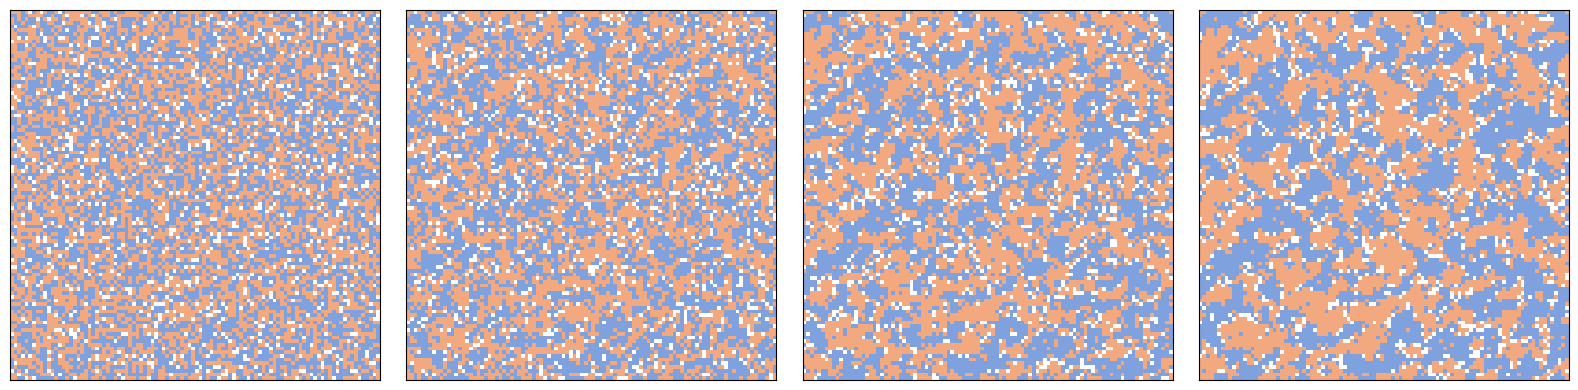

In [65]:
grid = Schelling(n=100, p=0.76)
# three_frame(grid, [0, 2, 8]) #step0,0+2,0+2+8
number_frame(grid,[0,2,3,5],4)

# 图 1：p=0.2 ～ 0.9的整体趋势
这张图主要用来观察不同满意度阈值p对segregation的整体影响。可以看到，p从0.2增加到0.8时，最终segregation总体上逐渐提高；但当p=0.9时，segregation反而下降，而且曲线持续波动。这说明segregation并不是随着p无限增加，而是在较高p附近达到峰值后开始下降。一个可能原因是，当满意度要求过高时，大量Agent很难找到满足条件的位置，因此不断随机搬家，系统反而难以稳定。

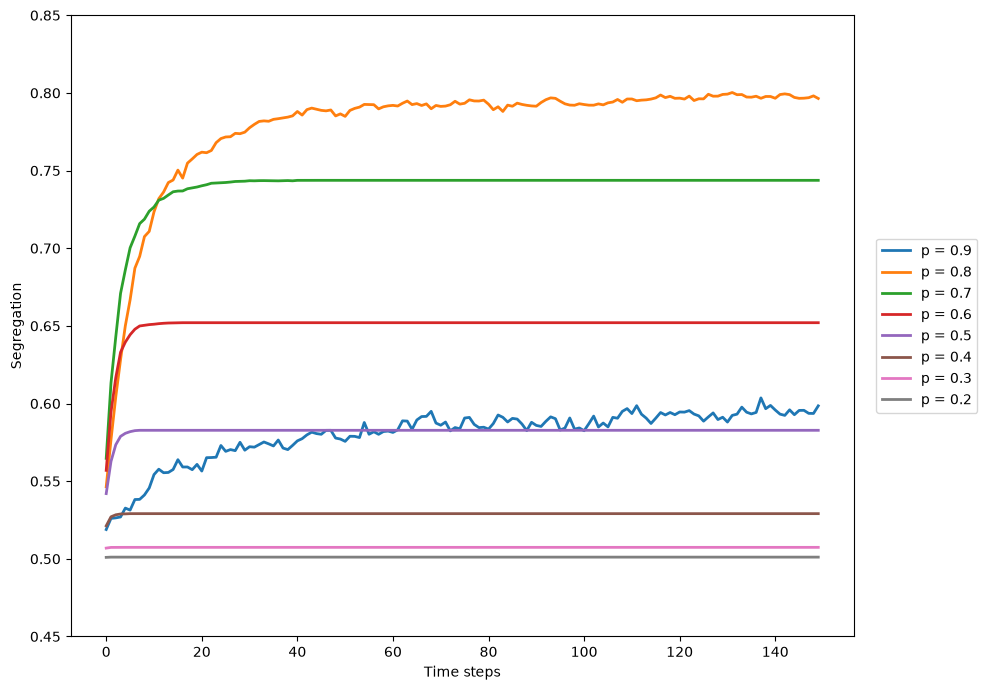

In [66]:
plt.figure(figsize=(10, 7))

for i, p in enumerate([0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]):

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(
        segs,
        label='p = %.1f' % p
    )

decorate(
    xlabel='Time steps',
    ylabel='Segregation', #Segregation 表示一个 Agent 周围的已占用邻居中，有多少比例和自己属于同一个 group，然后再对所有 Agent 取平均。
    ylim=[0.45, 0.85]
)

# 把 legend 放到图的右边外面
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 2：p=0.2 ～ 0.7的稳定速度
这张图主要用来看模型大约需要多少timestep才能稳定。低p情况，例如p=0.2 ～ 0.4，几乎马上稳定，因为大多数Agent一开始已经满足要求。随着p增加，模型需要更多timestep才能稳定，例如 \(p=0.6\) 和 \(p=0.7\) 大约需要15–30个timestep。总体上说明：在正常范围内，满意度要求越高，系统达到稳定状态所需要的时间越长。

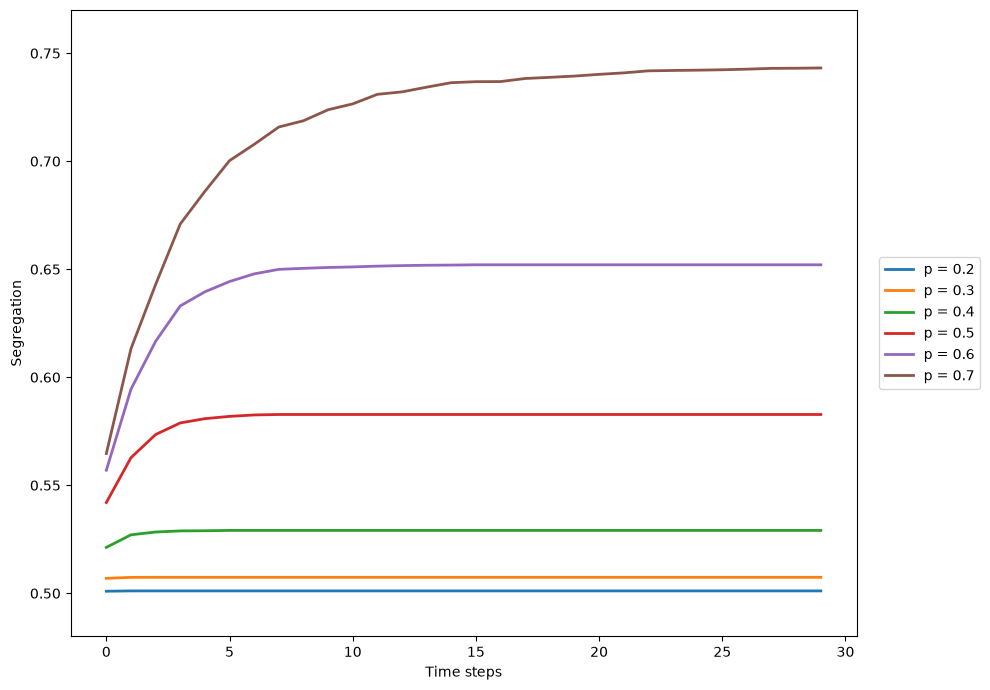

In [67]:
plt.figure(figsize=(10, 7))

for p in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(30)]

    plt.plot(segs, label='p = %.1f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.48, 0.77)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 3：p=0.7 ～ 0.9的高满意度区域
这张图把高p区域进一步放大。可以看到p=0.7到0.8时segregation较高，而且最后能够接近稳定；但是从大约p=0.85开始，最终segregation明显下降，同时曲线波动增加。到p=0.9时这种现象最明显。因此，高满意度要求并不一定导致更严重的segregation，反而可能使Agent长时间持续移动，导致系统难以达到equilibrium。

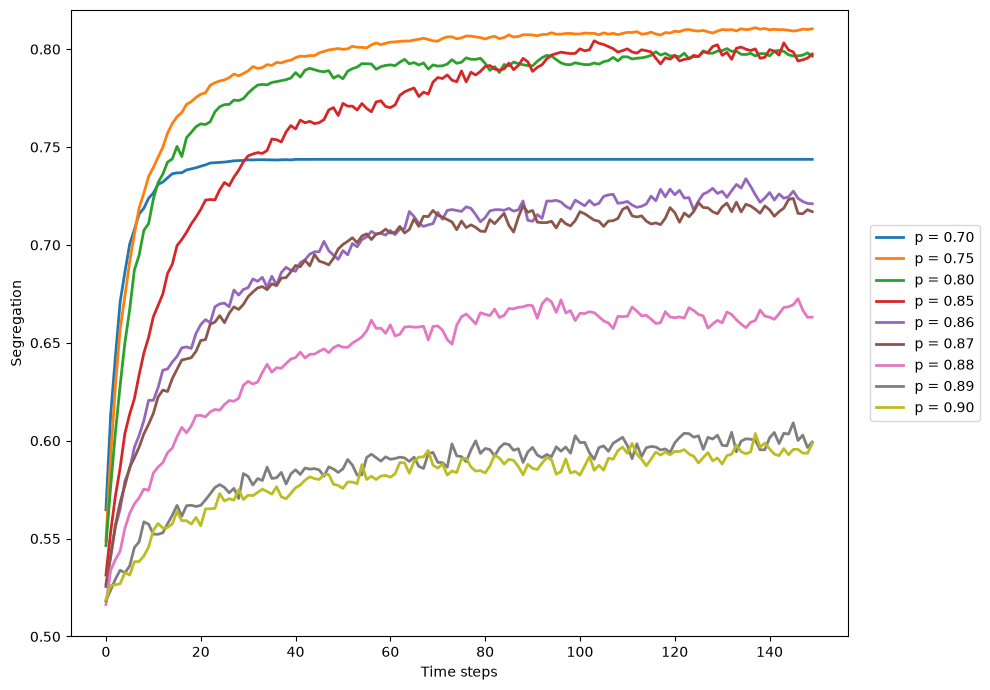

In [68]:
plt.figure(figsize=(10, 7))

for p in [0.7, 0.75, 0.8, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(segs, label='p = %.2f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.50, 0.82)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 4：p=0.75 ～ 0.80的峰值搜索
目前可以认为，在当前模型参数下，segregation的峰值区域大约位于p=0.76 ～ 0.77。这只是当前实验得到的数值峰值，之后还可以增加random seeds来确认它是否稳定。

p = 0.75, mean segregation = 0.8067
p = 0.76, mean segregation = 0.8231
p = 0.77, mean segregation = 0.8225
p = 0.78, mean segregation = 0.8064
p = 0.79, mean segregation = 0.8058
p = 0.80, mean segregation = 0.8058

Peak p = 0.76
Maximum segregation = 0.8230947792221363


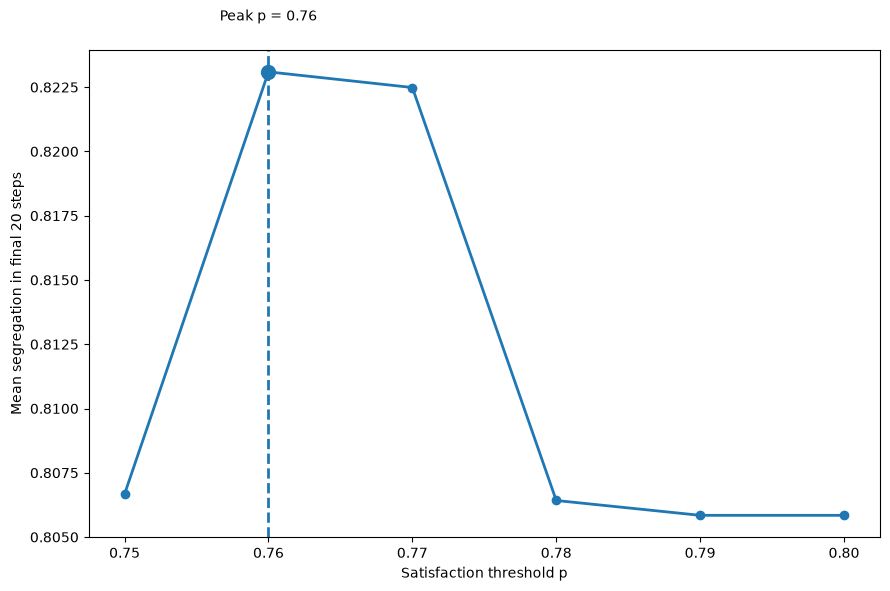

In [69]:
# Test p from 0.75 to 0.80
p_values = np.round(np.arange(0.75, 0.801, 0.01), 2)

seeds = range(5)
n_steps = 200
final_window = 20

mean_segs = []

for p in p_values:

    results = []

    for seed in seeds:

        np.random.seed(seed)

        grid = Schelling(n=100, p=p)

        segs = []

        for step in range(n_steps):
            grid.step()
            segs.append(grid.segregation())

        # Average segregation of the final 20 steps
        results.append(np.mean(segs[-final_window:]))

    # Average result from all seeds
    mean_segs.append(np.mean(results))

    print(f"p = {p:.2f}, "f"mean segregation = {np.mean(results):.4f}")

# Find the maximum
peak_index = np.argmax(mean_segs)

peak_p = p_values[peak_index]
peak_seg = mean_segs[peak_index]

print("\nPeak p =", peak_p)
print("Maximum segregation =", peak_seg)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(p_values, mean_segs, marker='o', linewidth=2)

# Mark the peak
plt.scatter(peak_p, peak_seg, s=100)

plt.axvline(peak_p, linestyle='--')

plt.text(peak_p, peak_seg + 0.002, f'Peak p = {peak_p:.2f}', ha='center')

plt.xlabel('Satisfaction threshold p')
plt.ylabel('Mean segregation in final 20 steps')

plt.xticks(p_values)

plt.tight_layout()
plt.show()